# Improved Home Credit models: experiments and submission

This notebook explains the executed experiments and reproduces the submission from saved models. To rerun training, use the commands below with the project venv. All original notebooks are preserved; all dataset rows come from `input/train.csv` and `input/test.csv`.

The five-feature random forest baseline follows the supplied `tutorial.ipynb`, with preprocessing fitted within the split to avoid its preprocessing leakage. New model code is original to this project; no external notebook code or dataset was downloaded.

In [1]:
from pathlib import Path
import sys, json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd() if (Path.cwd()/'input/train.csv').exists() else Path.cwd()/'Competition'
assert (ROOT/'input/train.csv').exists(), 'Run from the Competition directory or its parent.'
assert Path(sys.prefix).resolve() == (ROOT/'.venv').resolve(), 'Select the project local venv kernel.'
ART=ROOT/'improvements/artifacts'
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
train=pd.read_csv(ROOT/'input/train.csv'); test=pd.read_csv(ROOT/'input/test.csv')
print('Python:',sys.executable)

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python


## Reproduce the complete experiment

From `Competition`, run these commands in order. They perform the same seeded split, screening, five-fold development validation, one frozen audit evaluation, and final training. Repeatedly inspecting the audit and tuning against it would invalidate its independence.

```sh
.venv/bin/python improvements/experiment.py screen --trials 24
.venv/bin/python improvements/supplement.py
.venv/bin/python improvements/refine.py
.venv/bin/python improvements/select_features.py
.venv/bin/python improvements/refine_cat.py
.venv/bin/python improvements/experiment.py cv
.venv/bin/python improvements/experiment.py audit
.venv/bin/python improvements/experiment.py final
```

The package versions and original-file hashes are recorded under `improvements/artifacts`. Source, notebooks, models, results and submission are included in the reproduction ZIP.

In [2]:
# Set True to rerun the full search and training from this notebook (lengthy).
# False reuses the supplied, executed artifacts and saved models.
RUN_FULL_EXPERIMENT = False
if RUN_FULL_EXPERIMENT:
    import subprocess
    stages=[['experiment.py','screen','--trials','24'],['supplement.py'],['refine.py'],
            ['select_features.py'],['refine_cat.py'],['experiment.py','cv'],
            ['experiment.py','audit'],['experiment.py','final']]
    for stage in stages:
        subprocess.run([sys.executable,str(ROOT/'improvements'/stage[0]),*stage[1:]],cwd=ROOT,check=True)
else:
    print('Using the completed experiment; saved-model prediction is reproduced below.')

Using the completed experiment; saved-model prediction is reproduced below.


In [3]:
screen=json.loads((ART/'screen_results.json').read_text())
screen+=json.loads((ART/'supplement_results.json').read_text())
screen+=json.loads((ART/'refine_results.json').read_text())
screen+=json.loads((ART/'feature_selection_results.json').read_text())
screen+=json.loads((ART/'cat_refine_results.json').read_text())
table=pd.DataFrame([{k:v for k,v in row.items() if k!='spec'} for row in screen]).sort_values('auc',ascending=False)
display(table)

,name,auc,iterations,seconds
29,cat_depth4,0.748959,1828.0,163.195629
50,cat_lean,0.748493,1670.0,170.867230
56,cat_lean_depth6,0.748028,1395.0,188.158252
30,cat_depth5,0.747660,1464.0,128.312184
55,cat_lean_depth4,0.747615,1494.0,158.994229
32,cat_depth7,0.747337,932.0,162.358544
31,cat_depth6,0.747212,1016.0,155.899569
20,lgb_tune_15,0.747151,844.0,19.157273
17,lgb_tune_12,0.746578,849.0,18.415102
54,lgb_top_70,0.746336,709.0,31.650319


In [4]:
cv=json.loads((ART/'cv_results.json').read_text())
display(pd.DataFrame([{'model':r['name'],'pooled_oof_auc':r['auc'],'fold_mean':np.mean(r['fold_auc']),'fold_std':np.std(r['fold_auc'],ddof=1),'median_trees':int(np.median(r['iterations']))} for r in cv]).sort_values('pooled_oof_auc',ascending=False))
selection=json.loads((ART/'selection.json').read_text())
display(pd.DataFrame({'model':selection['names'],'weight':selection['weights']}))
print('Selected blend development OOF AUC:',selection['auc'])

,model,pooled_oof_auc,fold_mean,fold_std,median_trees
6,cat_lean,0.760790,0.760809,0.003068,1529
9,cat_lean_depth6,0.760148,0.760167,0.003514,1315
5,cat_depth4,0.759728,0.759737,0.003442,1404
1,lgb_tune_12,0.757388,0.757415,0.004126,601
0,lgb_tune_15,0.757328,0.757368,0.003944,590
2,lgb_top_70,0.756960,0.756993,0.004131,491
3,lgb_engineered,0.756102,0.756148,0.003752,375
7,hgb_20,0.753292,0.753264,0.003445,250
4,lgb_raw,0.749947,0.749965,0.004077,356
8,spline_0.1,0.748304,0.748309,0.002872,1


,model,weight
0,cat_lean,0.666667
1,lgb_tune_15,0.333333


Selected blend development OOF AUC: 0.7617724188892933


## Independent audit

The audit contains 20% of training rows, isolated before any model selection. Model choice, blend weights, categorical encoders and tree counts were frozen first. Its probabilities come from models fitted on development rows, with no audit early stopping. Paired stratified bootstrap confidence intervals quantify sampling uncertainty conditional on these fitted models; they do not capture every source of training or competition shift.

In [5]:
audit=json.loads((ART/'audit_results.json').read_text())
display(pd.DataFrame({'Tutorial RF':audit['baseline'],'Improved model':audit['improved']}))
print('Improved AUC 95% bootstrap interval:',audit['auc_ci95'])
print('Paired AUC gain 95% bootstrap interval:',audit['auc_gain_ci95'])
print('Optimistic in-sample development diagnostics:',audit['development_training'])

,Tutorial RF,Improved model
roc_auc,0.666573,0.755506
average_precision,0.156340,0.232825
log_loss,0.266718,0.247273
brier,0.071884,0.068233


Improved AUC 95% bootstrap interval: [0.746458044538711, 0.7649009442012354]
Paired AUC gain 95% bootstrap interval: [0.07968198671995681, 0.09785786624828456]
Optimistic in-sample development diagnostics: {'roc_auc': 0.8220405381451281, 'average_precision': 0.3780603848159751, 'log_loss': 0.22411818296729966, 'brier': 0.06238813167933921}


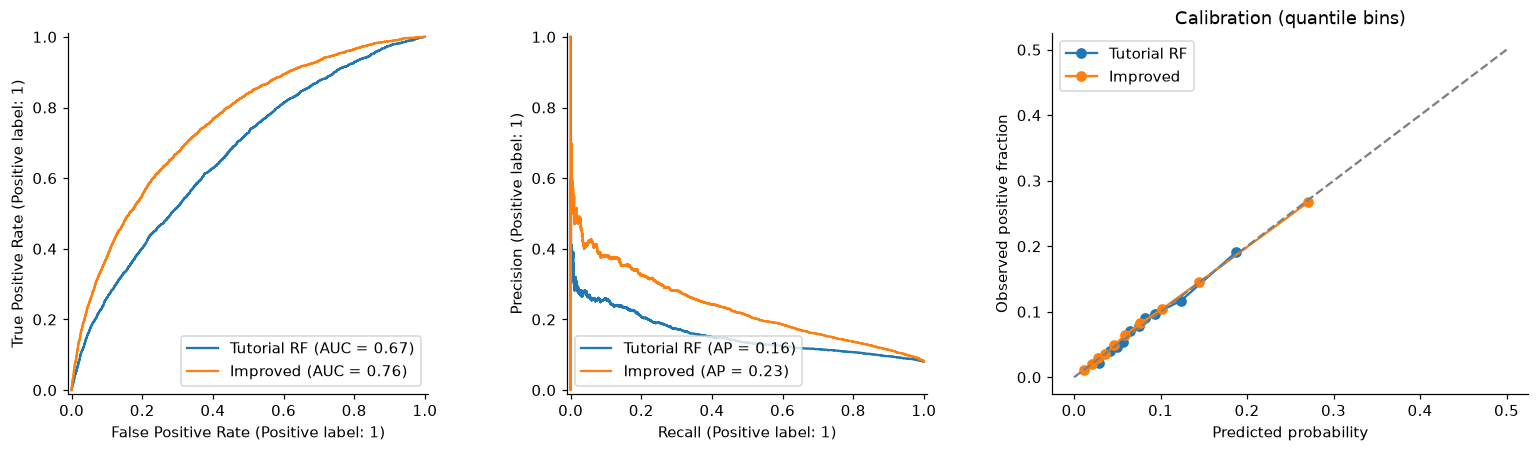

,feature,group,rows,defaults,auc
0,CODE_GENDER,F,22529,1588,0.752779
1,CODE_GENDER,M,11712,1176,0.748225
2,NAME_CONTRACT_TYPE,Cash loans,30988,2584,0.753991
3,NAME_CONTRACT_TYPE,Revolving loans,3253,180,0.756351
4,NAME_INCOME_TYPE,Commercial associate,7924,606,0.763467
5,NAME_INCOME_TYPE,Pensioner,6353,353,0.731021
6,NAME_INCOME_TYPE,State servant,2397,148,0.765139
7,NAME_INCOME_TYPE,Working,17562,1656,0.748684
8,NAME_EDUCATION_TYPE,Higher education,8241,469,0.765973
9,NAME_EDUCATION_TYPE,Incomplete higher,1130,102,0.724975


In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from sklearn.calibration import calibration_curve
a=np.load(ART/'audit_predictions.npz')
fig,axes=plt.subplots(1,3,figsize=(14,4),layout='constrained')
for key,label in [('baseline','Tutorial RF'),('improved','Improved')]:
    RocCurveDisplay.from_predictions(a['target'],a[key],name=label,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(a['target'],a[key],name=label,ax=axes[1])
    observed,predicted=calibration_curve(a['target'],a[key],n_bins=10,strategy='quantile')
    axes[2].plot(predicted,observed,'o-',label=label)
axes[2].plot([0,.5],[0,.5],'--',color='gray'); axes[2].legend()
axes[2].set(xlabel='Predicted probability',ylabel='Observed positive fraction',title='Calibration (quantile bins)')
plt.show()
display(pd.read_csv(ART/'audit_subgroups.csv'))

## Final training and feature importance

Five deterministic, stratified folds are fitted with fixed tree counts. Each row is held out from its own OOF model. Average the five test predictions within each family, then apply the frozen development blend weights. Numerical missing values are learned directly by LightGBM; CatBoost receives a numeric missing sentinel plus missing-derived features. Feature importance describes the model's use of each feature.

,name,iterations,full_oof_auc
0,cat_lean,1529,0.761318
1,lgb_tune_15,590,0.758201


Diagnostic full-data OOF: {'roc_auc': 0.7620607672390954, 'average_precision': 0.24454768410953534, 'log_loss': 0.2450978586391416, 'brier': 0.06768687762303752}
Full-data OOF is diagnostic: development labels previously influenced model selection. Use untouched audit for an independent estimate.


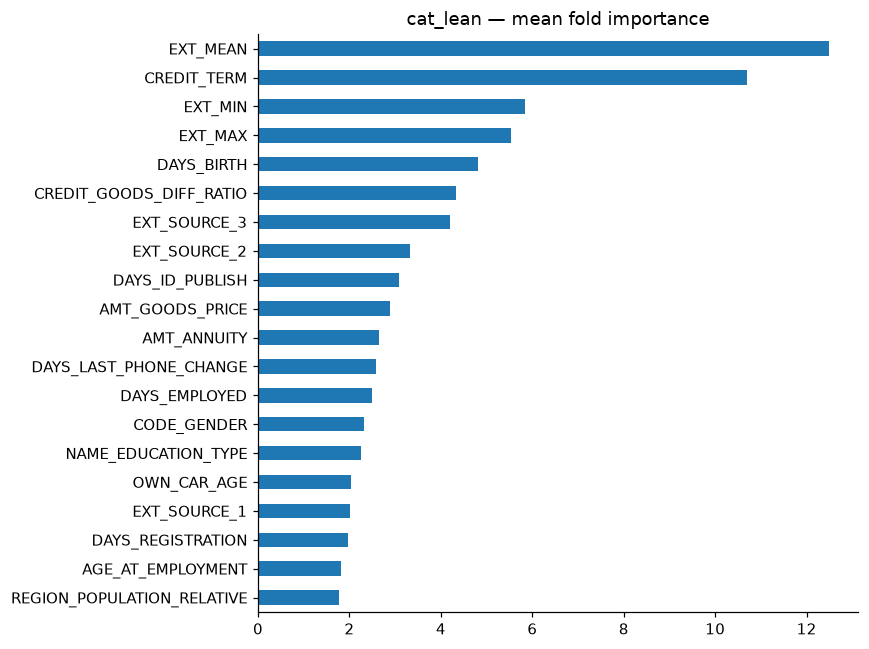

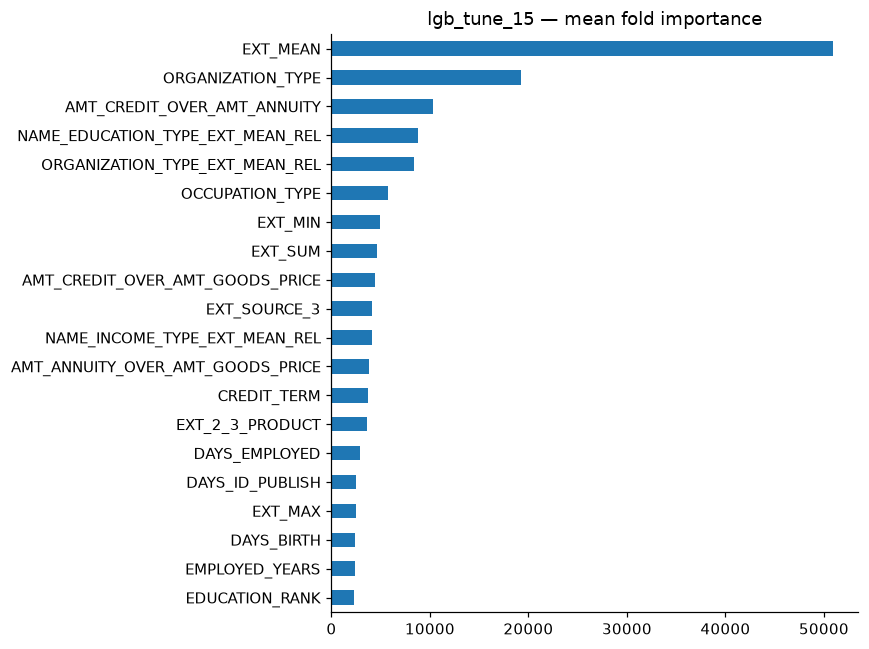

In [7]:
final=json.loads((ART/'final_results.json').read_text())
display(pd.DataFrame(final['models']))
print('Diagnostic full-data OOF:',final['full_oof'])
print(final['caveat'])
for name in selection['names']:
    if not (ART/(name+'_importance.csv')).exists(): continue
    importance=pd.read_csv(ART/(name+'_importance.csv'),index_col=0).iloc[:,0]
    importance.head(20).sort_values().plot.barh(figsize=(8,6),title=name+' — mean fold importance')
    plt.tight_layout(); plt.show()

## Recreate the exact submission from saved models

Run the following cell to predict the supplied test rows without retraining. It recreates the encoders, loads each saved model, averages probabilities and checks the file against the stored SHA-256 checksum. This takes longer than displaying the results above but much less time than rerunning the search.

In [8]:
import sys, hashlib, joblib
sys.path.insert(0,str(ROOT/'improvements'))
from experiment import features, Encoder
import lightgbm as lgb
from catboost import CatBoostClassifier
prediction=np.zeros(len(test))
for weight,row in zip(selection['weights'],selection['models']):
    spec=row['spec']; xt=features(test,spec['features']); family_prediction=np.zeros(len(test))
    for fold in range(5):
        prefix=ROOT/'improvements/models'/f"{row['name']}_fold{fold}"
        encoder=Encoder(); encoder.__dict__.update(joblib.load(str(prefix)+'_encoder.joblib'))
        if spec['kind']=='lgb':
            model=lgb.Booster(model_file=str(prefix)+'.txt')
            p=model.predict(encoder.transform(xt),num_threads=4)
        elif spec['kind']=='cat':
            model=CatBoostClassifier(); model.load_model(str(prefix)+'.cbm')
            p=model.predict_proba(encoder.transform(xt))[:,1]
        else:
            model=joblib.load(str(prefix)+'.joblib')
            p=model.predict_proba(encoder.transform(xt))[:,1]
        family_prediction+=p/5
    prediction+=weight*family_prediction
submission=pd.read_csv(ROOT/'input/sample_submission.csv')
assert submission.SK_ID_CURR.equals(test.SK_ID_CURR)
assert np.isfinite(prediction).all() and ((0<=prediction)&(prediction<=1)).all()
submission['TARGET']=prediction
reproduced=ROOT/'output/submission_reproduced.csv'
submission.to_csv(reproduced,index=False)
actual=hashlib.sha256(reproduced.read_bytes()).hexdigest()
assert actual==final['sha256'], (actual,final['sha256'])
print('Exact submission reproduced:',reproduced)
display(submission.head())

/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Exact submission reproduced: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/output/submission_reproduced.csv


,SK_ID_CURR,TARGET
0,171202,0.031512
1,171203,0.184580
2,171204,0.146358
3,171205,0.113746
4,171206,0.186537


## Submission and limitations

Upload `output/submission_improved.csv` to Omnicampus. The local README says the final ranking uses your **last** submission. Upload the reproduction ZIP as code evidence if seeking Honors/Outstanding Student. No competition-platform submission is performed by this notebook.

The hidden test score remains unknown. Tiny CV differences may be noise. More searches can overfit development predictions, and there is no defensible way to guarantee a global optimum. The stopping decision is based on diminishing returns across model families, feature variants, regularization settings, validation folds and simple blends. Do not use the independent audit repeatedly to select additional variants.